In [12]:
# PHASE 1: PROBLEM DEFINITION

project_title = "Which Product Category Receives Higher Ratings?"

objective = """
To analyse customer reviews and identify which product
categories receive the highest average customer ratings.
"""

research_questions = [
    "Which department receives the highest average rating?",
    "Which product class receives the highest average rating?",
    "How are customer ratings distributed?",
    "Is there a significant difference in ratings between categories?"
]

print("PROJECT TITLE:", project_title)
print("\nOBJECTIVE:")
print(objective)

print("\nRESEARCH QUESTIONS:")
for i, question in enumerate(research_questions, 1):
    print(f"{i}. {question}")

PROJECT TITLE: Which Product Category Receives Higher Ratings?

OBJECTIVE:

To analyse customer reviews and identify which product
categories receive the highest average customer ratings.


RESEARCH QUESTIONS:
1. Which department receives the highest average rating?
2. Which product class receives the highest average rating?
3. How are customer ratings distributed?
4. Is there a significant difference in ratings between categories?


In [13]:
# PHASE 2: DATASET UNDERSTANDING

# Step 1: Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
from google.colab import files

# Step 2: Upload CSV File
uploaded = files.upload()

# Step 3: Read CSV File (handling potential zip archive uploads)
file_name = list(uploaded.keys())[0]
if file_name.endswith('.zip'):
    import zipfile

    # Extracting file from in-memory bytes safely
    with zipfile.ZipFile(io.BytesIO(uploaded[file_name]), 'r') as zip_ref:
        zip_ref.extractall()
        extracted_file_name = zip_ref.namelist()[0]
    df = pd.read_csv(extracted_file_name)
else:
    df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Step 4: Display Dataset
print("Dataset uploaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

# Step 5: Column Names
print("\nColumn Names:")
print(df.columns.tolist())

# Step 6: Dataset Information
print("\nDataset Information:")
df.info()

# Step 7: Missing Values
print("\nMissing Values:")
display(df.isnull().sum())

# Step 8: Statistical Summary
print("\nStatistical Summary:")
display(df.describe())

Saving archive (1).zip to archive (1) (1).zip
Dataset uploaded successfully!
Dataset Shape: (23486, 11)

First 5 Rows:


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses



Column Names:
['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Unnamed: 0               23486 non-null  int64 
 1   Clothing ID              23486 non-null  int64 
 2   Age                      23486 non-null  int64 
 3   Title                    19676 non-null  object
 4   Review Text              22641 non-null  object
 5   Rating                   23486 non-null  int64 
 6   Recommended IND          23486 non-null  int64 
 7   Positive Feedback Count  23486 non-null  int64 
 8   Division Name            23472 non-null  object
 9   Department Name          23472 non-null  object
 10  Class Name               23472 non-null  objec

,0
Unnamed: 0,0
Clothing ID,0
Age,0
Title,3810
Review Text,845
Rating,0
Recommended IND,0
Positive Feedback Count,0
Division Name,14
Department Name,14



Statistical Summary:


,Unnamed: 0,Clothing ID,Age,Rating,Recommended IND,Positive Feedback Count
count,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000,23486.000000
mean,11742.500000,918.118709,43.198544,4.196032,0.822362,2.535936
std,6779.968547,203.298980,12.279544,1.110031,0.382216,5.702202
min,0.000000,0.000000,18.000000,1.000000,0.000000,0.000000
25%,5871.250000,861.000000,34.000000,4.000000,1.000000,0.000000
50%,11742.500000,936.000000,41.000000,5.000000,1.000000,1.000000
75%,17613.750000,1078.000000,52.000000,5.000000,1.000000,3.000000
max,23485.000000,1205.000000,99.000000,5.000000,1.000000,122.000000


In [9]:
# Check actual column names

print("Available columns:")
for col in df.columns:
    print(repr(col))

Available columns:
'customer_id'
'customer_name'
'customer_age'
'gender'
'customer_segment'
'customer_city'
'customer_state'
'customer_country'
'region'
'customer_postal_code'
'customer_acquisition_cost'


In [16]:
# PHASE 3: DATA PREPARATION

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Check required columns
required_columns = ["Rating", "Department Name", "Class Name"]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    print("Wrong dataset! Missing columns:", missing_columns)
else:
    # Remove unnecessary index column
    df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

    # Remove duplicate records
    df = df.drop_duplicates()

    # Convert Rating into numeric values
    df["Rating"] = pd.to_numeric(
        df["Rating"], errors="coerce"
    )

    # Remove missing and invalid ratings
    df = df.dropna(subset=["Rating"])
    df = df[df["Rating"].between(1, 5)]

    # Remove missing category names
    df = df.dropna(
        subset=["Department Name", "Class Name"]
    )

    print("Data Cleaning Completed!")
    print("Cleaned Dataset Shape:", df.shape)
    display(df.head())

Data Cleaning Completed!
Cleaned Dataset Shape: (23451, 10)


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


In [17]:
# Missing Values Analysis

print("Missing Values in Each Column:")
display(df.isnull().sum())

print("Total Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

Missing Values in Each Column:


,0
Clothing ID,0
Age,0
Title,3788
Review Text,824
Rating,0
Recommended IND,0
Positive Feedback Count,0
Division Name,0
Department Name,0
Class Name,0


Total Missing Values: 4612
Duplicate Rows: 0


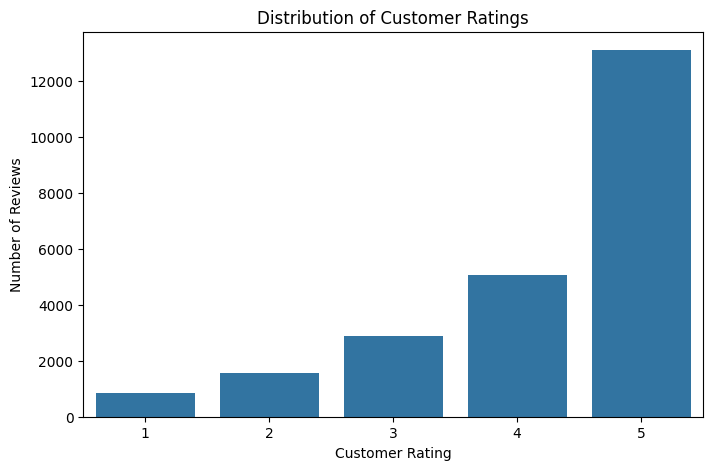

In [20]:
# Customer Rating Distribution

plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Rating")

plt.title("Distribution of Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Reviews")

plt.show()

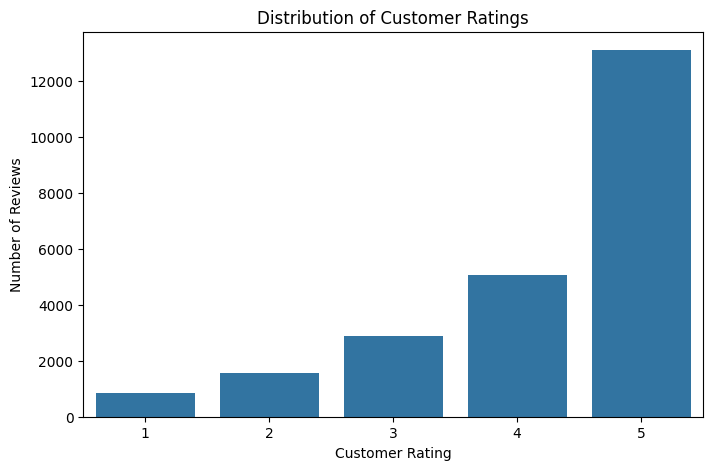

In [21]:
# Customer Rating Distribution

plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Rating")

plt.title("Distribution of Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Reviews")

plt.show()

Average Rating by Department:


,Rating
Department Name,
Bottoms,4.288573
Intimate,4.280115
Jackets,4.264535
Tops,4.171306
Dresses,4.149873
Trend,3.815126


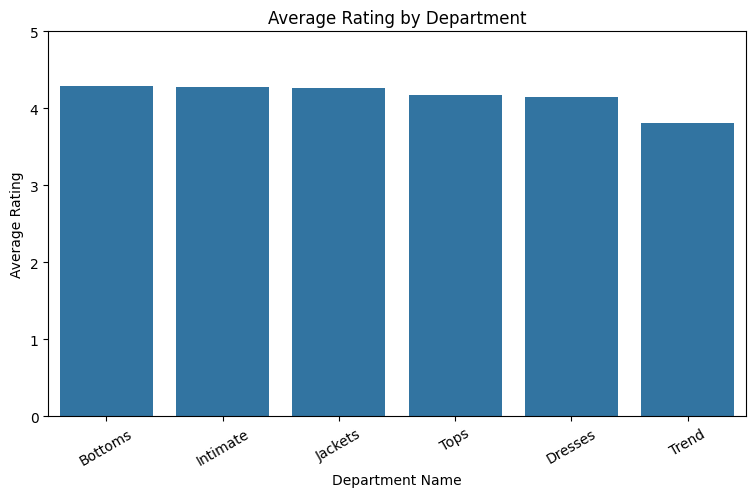

In [22]:
# Department Wise Average Rating

department_rating = df.groupby(
    "Department Name"
)["Rating"].mean().sort_values(ascending=False)

print("Average Rating by Department:")
display(department_rating)

plt.figure(figsize=(9,5))

sns.barplot(
    x=department_rating.index,
    y=department_rating.values
)

plt.title("Average Rating by Department")
plt.xlabel("Department Name")
plt.ylabel("Average Rating")
plt.ylim(0,5)
plt.xticks(rotation=30)

plt.show()

In [23]:
# PHASE 4: DATA ANALYSIS

class_rating = df.groupby("Class Name")["Rating"].agg(
    ["mean", "count"]
)

# Consider categories with at least 20 reviews
class_rating = class_rating[class_rating["count"] >= 20]

class_rating = class_rating.sort_values(
    by="mean", ascending=False
)

print("Top 10 Highest Rated Product Categories:")
display(class_rating.head(10))

Top 10 Highest Rated Product Categories:


,mean,count
Class Name,,
Layering,4.376712,146
Jeans,4.360384,1146
Lounge,4.301013,691
Jackets,4.295455,704
Sleep,4.285088,228
Intimates,4.279221,154
Legwear,4.278788,165
Pants,4.265850,1388
Fine gauge,4.260237,1099


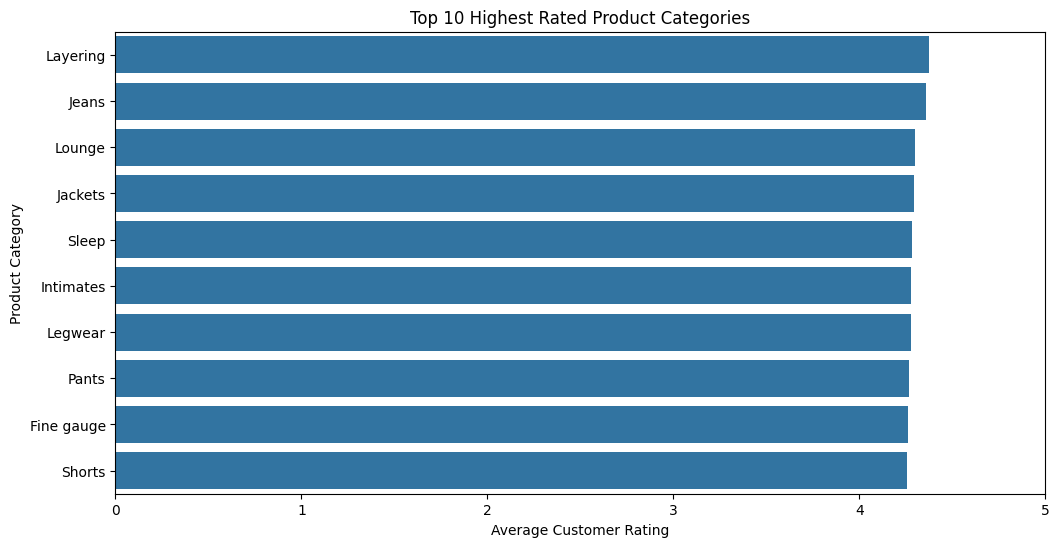

In [24]:
# Visualization of Top 10 Product Categories

top_10 = class_rating.head(10).reset_index()

plt.figure(figsize=(12,6))

sns.barplot(
    data=top_10,
    x="mean",
    y="Class Name"
)

plt.title("Top 10 Highest Rated Product Categories")
plt.xlabel("Average Customer Rating")
plt.ylabel("Product Category")
plt.xlim(0,5)

plt.show()

In [25]:
# Kruskal-Wallis Statistical Test

from scipy.stats import kruskal

groups = []

for name, group in df.groupby("Department Name"):
    ratings = group["Rating"].dropna()

    if len(ratings) >= 20:
        groups.append(ratings)

if len(groups) >= 2:

    statistic, p_value = kruskal(*groups)

    print("Kruskal-Wallis Test Results")
    print("Test Statistic:", statistic)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("Significant difference found between departments.")
    else:
        print("No significant difference found between departments.")

else:
    print("Not enough groups for statistical testing.")

Kruskal-Wallis Test Results
Test Statistic: 79.12048981761424
P-value: 1.2817897347287647e-15
Significant difference found between departments.


In [26]:
# PHASE 5: FINAL RESULTS

best_department = department_rating.idxmax()
best_department_score = department_rating.max()

best_class = class_rating["mean"].idxmax()
best_class_score = class_rating["mean"].max()

overall_rating = df["Rating"].mean()

print("========== FINAL PROJECT RESULTS ==========")

print("Total Reviews:", len(df))

print("Overall Average Rating:",
      round(overall_rating, 2))

print("\nHighest Rated Department:",
      best_department)

print("Department Average Rating:",
      round(best_department_score, 2))

print("\nHighest Rated Product Category:",
      best_class)

print("Category Average Rating:",
      round(best_class_score, 2))

========== FINAL PROJECT RESULTS ==========
Total Reviews: 23451
Overall Average Rating: 4.19

Highest Rated Department: Bottoms
Department Average Rating: 4.29

Highest Rated Product Category: Layering
Category Average Rating: 4.38


In [27]:
# PROJECT CONCLUSION

print("========== PROJECT CONCLUSION ==========")

print(
    f"The highest rated department is {best_department} "
    f"with an average rating of {best_department_score:.2f}."
)

print(
    f"The highest rated product category is {best_class} "
    f"with an average rating of {best_class_score:.2f}."
)

print(
    f"The overall average customer rating is {overall_rating:.2f}."
)

print("\nThe analysis helps identify customer satisfaction "
      "across different retail product categories.")

========== PROJECT CONCLUSION ==========
The highest rated department is Bottoms with an average rating of 4.29.
The highest rated product category is Layering with an average rating of 4.38.
The overall average customer rating is 4.19.

The analysis helps identify customer satisfaction across different retail product categories.


In [28]:
# PROJECT LIMITATIONS

limitations = [
    "The dataset represents one women's clothing retailer.",
    "Customer ratings are subjective.",
    "Some categories have fewer customer reviews.",
    "The analysis does not directly measure product sales.",
    "The results may not represent all retail customers."
]

print("PROJECT LIMITATIONS")

for i, item in enumerate(limitations, 1):
    print(f"{i}. {item}")

PROJECT LIMITATIONS
1. The dataset represents one women's clothing retailer.
2. Customer ratings are subjective.
3. Some categories have fewer customer reviews.
4. The analysis does not directly measure product sales.
5. The results may not represent all retail customers.
